# Wind forecast accuracy — January 2026

Exploration behind the app. Uses the same tested modules as the backend (`backend/app`), so every number here matches the API.

- Actuals: Elexon FUELHH (`fuelType=WIND`), half-hourly, compared on the hour
- Forecasts: Elexon WINDFOR, hourly, 8 publishes/day
- Error `e = forecast − actual` (positive = forecast too high = **shortfall** for the buyer)

In [1]:
import sys; sys.path.insert(0, "../backend")
from datetime import date
import pandas as pd, matplotlib.pyplot as plt
from app.data import load_actuals, load_forecasts, hourly_actuals
from app.forecast import select_at_horizon, select_day_ahead, join_actuals
from app.metrics import summary, shortfall_stats, by_horizon, by_level
from app.buffer import buffer_table, apply_buffer, coverage, backtest

actuals, forecasts = load_actuals(), load_forecasts()
hourly = hourly_actuals(actuals)
print(len(actuals), "actual half-hours |", len(forecasts), "forecast rows |", forecasts.publishTime.nunique(), "publishes")

1632 actual half-hours | 14847 forecast rows | 256 publishes


## 1. January actuals

windiest: 2026-01-27 16409 MW | calmest: 2026-01-08 4528 MW


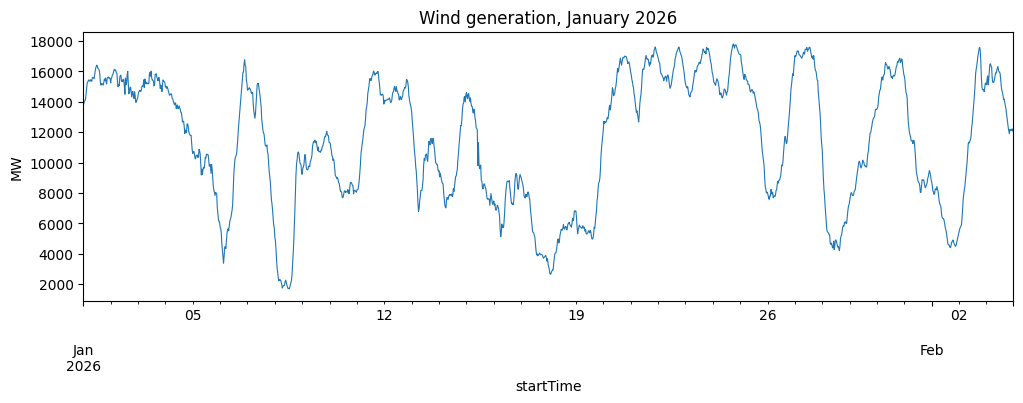

In [2]:
daily = actuals.set_index("startTime").generation.resample("D").mean()
ax = actuals.plot(x="startTime", y="generation", figsize=(12, 3.5), legend=False, lw=0.8)
ax.set_ylabel("MW"); ax.set_title("Wind generation, January 2026")
print("windiest:", daily.idxmax().date(), round(daily.max()), "MW | calmest:", daily.idxmin().date(), round(daily.min()), "MW")

## 2. Finding 1 — the forecast is almost always too high

In [3]:
rows = []
for h in (1, 4, 12, 24, 36, 48):
    p = join_actuals(select_at_horizon(forecasts, h), hourly)
    rows.append({"horizon_h": h, **summary(p), **shortfall_stats(p.error)})
pd.DataFrame(rows).set_index("horizon_h")[["mae", "bias", "p10", "p90", "shortfall_freq", "count"]]

,mae,bias,p10,p90,shortfall_freq,count
horizon_h,,,,,,
1,1753.1,1516.8,-416.4,3760.3,85.6,790
4,1786.3,1562.9,-259.0,3806.4,86.5,790
12,1842.2,1616.9,-263.3,3803.5,85.8,790
24,1965.4,1736.9,-399.6,4011.8,85.4,787
36,2138.6,1796.6,-770.4,4178.6,81.5,775
48,2262.8,1735.0,-964.1,4458.0,82.4,608


In [4]:
p1 = join_actuals(select_at_horizon(forecasts, 1), hourly)
print(f"actual / forecast overall: {p1.actual.sum() / p1.forecast.sum():.3f}")

actual / forecast overall: 0.883


## 3. Finding 2 — the bias explodes at high wind (likely curtailment)

In [5]:
da = join_actuals(select_day_ahead(forecasts, date(2026, 1, 1), date(2026, 2, 1)), hourly)
pd.DataFrame(by_level(da))

,bucket,bias,mae,count
0,<6 GW,789.6,1294.0,63
1,6-10 GW,733.1,1530.3,182
2,10-14 GW,1666.2,1752.8,163
3,>14 GW,2626.6,2667.6,360


forecast max 21064.0 | actual max 17805.0


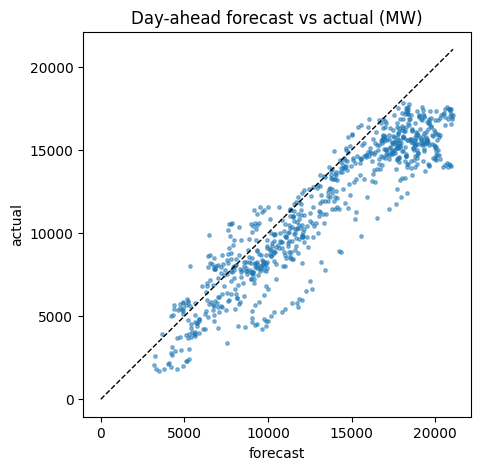

In [6]:
ax = da.plot.scatter(x="forecast", y="actual", s=6, alpha=0.5, figsize=(5, 5))
lim = [0, da.forecast.max()]; ax.plot(lim, lim, "k--", lw=1)
ax.set_title("Day-ahead forecast vs actual (MW)")
print("forecast max", da.forecast.max(), "| actual max", actuals.generation.max())

## 4. Finding 3 — bias is flat, spread grows with horizon

,mae,rmse,bias,spread,count
horizon,,,,,
1,1753.1,2243.7,1516.8,4176.7,790
12,1842.2,2324.7,1616.9,4066.8,790
24,1965.4,2438.4,1736.9,4411.4,787
48,2262.8,2838.3,1735.0,5422.1,608


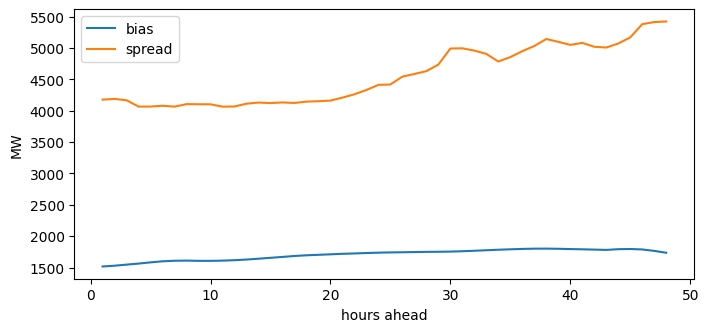

In [7]:
bh = pd.DataFrame(by_horizon(forecasts, hourly))
ax = bh.plot(x="horizon", y=["bias", "spread"], figsize=(8, 3.5))
ax.set_ylabel("MW"); ax.set_xlabel("hours ahead")
bh.set_index("horizon").loc[[1, 12, 24, 48]]

## 5. Day-ahead decisions and the safe-wind buffer

Day-ahead = latest forecast before 09:20 UK on D−1 (EPEX gate closure) → the 07:30 UTC publish.
Safe wind = `forecast − P90(error)` per wind-level bucket.

In [8]:
print(summary(da)); print(shortfall_stats(da.error))
buffer_table(da, 0.9).rows

{'mae': 2091.2, 'rmse': 2571.5, 'bias': 1823.4, 'nmae': 18.3, 'p10': -406.2, 'p50': 1637.5, 'p90': 4250.8, 'max': 6894.0, 'count': 768}
{'shortfall_p90': 4250.8, 'shortfall_freq': 85.2, 'mean_shortfall': 2298.5}


,bucket,q_low,q_high,n,pooled
0,<6 GW,-839.0,2189.4,63,False
1,6-10 GW,-1526.9,2580.2,182,False
2,10-14 GW,-59.0,3245.6,163,False
3,>14 GW,617.6,4784.4,360,False


In [9]:
days = list(pd.date_range("2026-01-01", "2026-02-01").date)
bt = backtest(forecasts, da, days, 0.9)
print("in-sample coverage:", coverage(apply_buffer(da, buffer_table(da, 0.9))), "%")
print("backtest coverage (no look-ahead):", coverage(bt), "%  | days on fallback:", bt[bt.fallback].day.nunique())

in-sample coverage: 89.7 %
backtest coverage (no look-ahead): 86.6 %  | days on fallback: 8


## 6. Replay candidate — 27 Jan (windiest)

forecast 477 GWh | safe 358 GWh | actual 395 GWh | held 23/24 h


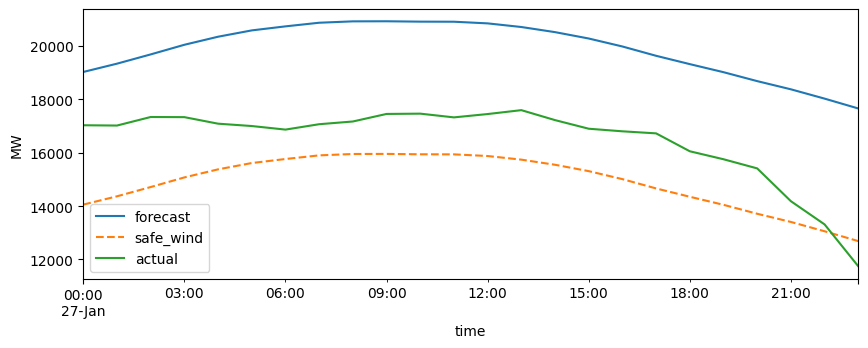

In [10]:
d = bt[bt.day == date(2026, 1, 27)]
ax = d.plot(x="time", y=["forecast", "safe_wind", "actual"], figsize=(10, 3.5), style=["-", "--", "-"])
ax.set_ylabel("MW")
print(f"forecast {d.forecast.sum()/1e3:.0f} GWh | safe {d.safe_wind.sum()/1e3:.0f} GWh | actual {d.actual.sum()/1e3:.0f} GWh | held {(d.actual >= d.safe_wind).sum()}/24 h")

## Headline insights

1. **The raw forecast overstates usable wind by ~12%.** Day-ahead it is typically ~1.8 GW too high and too high in ~85% of hours.
2. **Stormy hours are worst:** above 14 GW forecast the over-forecast averages ~2.6 GW, and actual never exceeds ~17.8 GW while forecasts reach ~21 GW. Likely curtailment (wind farms paid to switch off when the grid is full); not confirmed from the dataset docs.
3. **Buying later doesn't remove the bias, but narrows the uncertainty:** spread (P90−P10) grows from ~4.2 GW at 1h to ~5.4 GW at 48h.
4. **A per-wind-level safe-wind buffer works:** ~87% coverage in an honest backtest vs a 90% target (~90% in-sample). On 27 Jan it held in 23 of 24 hours while the raw forecast was 82 GWh too high.